In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Environment Ready!")

TensorFlow Version: 2.21.0
NumPy Version: 2.2.6
Environment Ready!


In [2]:
import os

dataset_path = "../dataset/cifar-10-batches-py"

print("Dataset exists:", os.path.exists(dataset_path))
print("\nDataset files:")

print(os.listdir(dataset_path))

Dataset exists: True

Dataset files:
['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


## Task 1 – Data Preparation

Perform data loading and preprocessing.



Tasks include:

- Load the dataset
- Explore the dataset
- Resize images (if required)
- Normalize pixel values
- Train-Test Split
- Visualize sample images
- Handle class labels

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
dataset_path = "../dataset/cifar-10-batches-py"

def load_batch(file_path):

    with open(file_path, "rb") as file:
        batch = pickle.load(file, encoding="bytes")

    images = batch[b"data"]
    labels = batch[b"labels"]

    images = images.reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)

    return images, np.array(labels)


X_train = []
y_train = []

for i in range(1, 6):

    file_path = os.path.join(dataset_path, f"data_batch_{i}")

    images, labels = load_batch(file_path)

    X_train.append(images)
    y_train.append(labels)

X_train = np.concatenate(X_train)
y_train = np.concatenate(y_train)

test_path = os.path.join(dataset_path, "test_batch")

X_test, y_test = load_batch(test_path)

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

Training Images: (50000, 32, 32, 3)
Training Labels: (50000,)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000,)


In [10]:
print("Training Data Information")
print("--------------------------")

print("Shape:", X_train.shape)
print("Data Type:", X_train.dtype)
print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

print("\nTesting Data Information")
print("--------------------------")

print("Shape:", X_test.shape)
print("Data Type:", X_test.dtype)
print("Minimum Pixel Value:", X_test.min())
print("Maximum Pixel Value:", X_test.max())

Training Data Information
--------------------------
Shape: (50000, 32, 32, 3)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255

Testing Data Information
--------------------------
Shape: (10000, 32, 32, 3)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255


In [11]:
meta_path = os.path.join(dataset_path, "batches.meta")

with open(meta_path, "rb") as file:
    metadata = pickle.load(file, encoding="bytes")

class_names = [
    name.decode("utf-8")
    for name in metadata[b"label_names"]
]

print("Classes:", class_names)

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [12]:
class_counts = pd.Series(y_train).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": class_names,
    "Number of Images": class_counts.values
})

print(class_distribution)

        Class  Number of Images
0    airplane              5000
1  automobile              5000
2        bird              5000
3         cat              5000
4        deer              5000
5         dog              5000
6        frog              5000
7       horse              5000
8        ship              5000
9       truck              5000


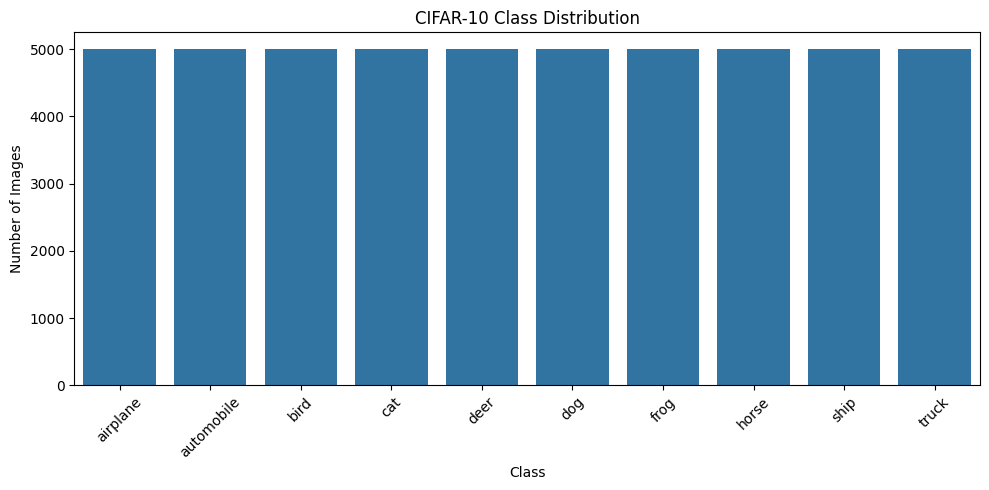

In [13]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_distribution,
    x="Class",
    y="Number of Images"
)

plt.title("CIFAR-10 Class Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

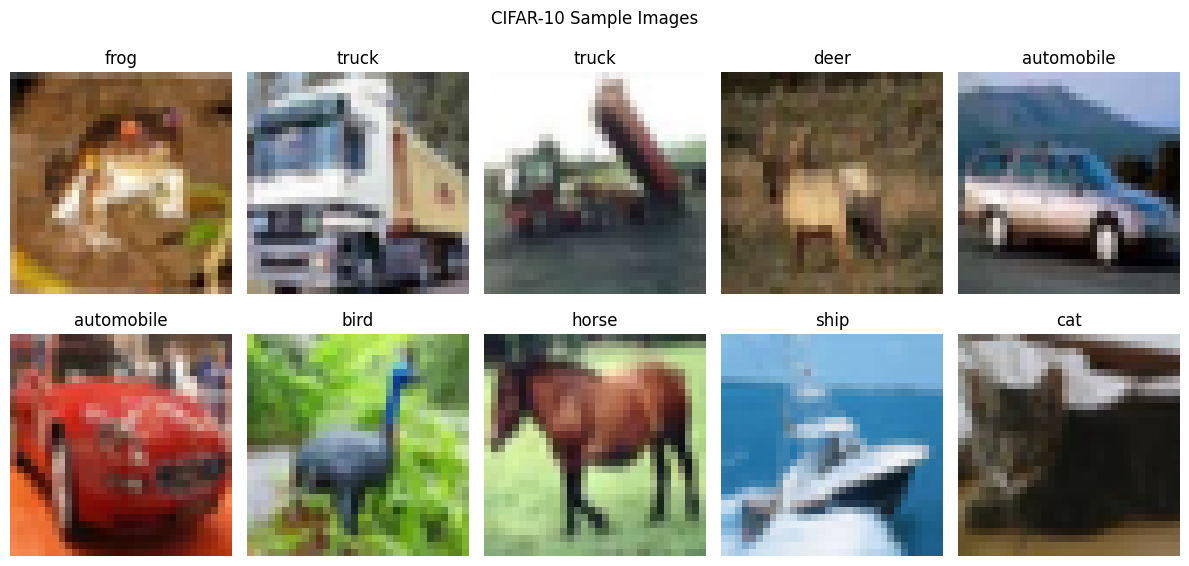

In [14]:
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i])

    plt.title(class_names[y_train[i]])

    plt.axis("off")

plt.suptitle("CIFAR-10 Sample Images")
plt.tight_layout()
plt.show()

In [21]:
# Resize only a small sample of images

X_train_resized = tf.image.resize(
    X_train[:100],
    (224, 224)
)

X_test_resized = tf.image.resize(
    X_test[:100],
    (224, 224)
)

print("Training Resized Images:", X_train_resized.shape)
print("Testing Resized Images:", X_test_resized.shape)

Training Resized Images: (100, 224, 224, 3)
Testing Resized Images: (100, 224, 224, 3)


In [23]:
# Normalize images using float32 in smaller batches

X_train_normalized = [
    X_train[i:i+1000].astype("float32") / 255.0
    for i in range(0, len(X_train), 1000)
]

X_test_normalized = [
    X_test[i:i+1000].astype("float32") / 255.0
    for i in range(0, len(X_test), 1000)
]

print("Training batches:", len(X_train_normalized))
print("Testing batches:", len(X_test_normalized))

print("First batch shape:", X_train_normalized[0].shape)

print("Minimum pixel value:", X_train_normalized[0].min())
print("Maximum pixel value:", X_train_normalized[0].max())

Training batches: 50
Testing batches: 10
First batch shape: (1000, 32, 32, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [24]:
from sklearn.model_selection import train_test_split

# Create training and validation indices
train_indices, val_indices = train_test_split(
    np.arange(len(y_train)),
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Split labels
y_train_final = y_train[train_indices]
y_val = y_train[val_indices]

# Keep test labels
y_test_final = y_test

print("Training Images:", len(train_indices))
print("Validation Images:", len(val_indices))
print("Testing Images:", len(y_test_final))

print("Training Labels:", y_train_final.shape)
print("Validation Labels:", y_val.shape)
print("Testing Labels:", y_test_final.shape)

Training Images: 40000
Validation Images: 10000
Testing Images: 10000
Training Labels: (40000,)
Validation Labels: (10000,)
Testing Labels: (10000,)


In [25]:
print("Numerical Labels:", y_train_final[:10])

print("\nCorresponding Class Names:")

for label in y_train_final[:10]:
    print(class_names[label])

Numerical Labels: [6 7 8 3 2 2 6 1 4 9]

Corresponding Class Names:
frog
horse
ship
cat
bird
bird
frog
automobile
deer
truck


In [26]:
from tensorflow.keras.utils import to_categorical

num_classes = 10

y_train_encoded = to_categorical(
    y_train_final,
    num_classes
)

y_val_encoded = to_categorical(
    y_val,
    num_classes
)

y_test_encoded = to_categorical(
    y_test_final,
    num_classes
)

print("Training Labels:", y_train_encoded.shape)
print("Validation Labels:", y_val_encoded.shape)
print("Testing Labels:", y_test_encoded.shape)

Training Labels: (40000, 10)
Validation Labels: (10000, 10)
Testing Labels: (10000, 10)


In [27]:
print("========== TASK 1: DATA PREPARATION ==========")

print("\n1. DATASET LOADING")
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\n2. DATASET EXPLORATION")
print("Data Type:", X_train.dtype)
print("Pixel Range:", X_train.min(), "-", X_train.max())

print("\n3. IMAGE RESIZING")
print("Original Size:", X_train.shape[1:])

print("Sample Resized Size:", X_train_resized.shape[1:])

print("\n4. NORMALIZATION")
print("Normalized Range:",
      X_train_normalized[0].min(),
      "-",
      X_train_normalized[0].max())

print("\n5. TRAIN-VALIDATION-TEST SPLIT")
print("Training:", len(train_indices))
print("Validation:", len(val_indices))
print("Testing:", len(y_test_final))

print("\n6. CLASS LABELS")
print("Classes:", class_names)
print("Number of Classes:", num_classes)

print("\n7. ONE-HOT ENCODING")
print("Training:", y_train_encoded.shape)
print("Validation:", y_val_encoded.shape)
print("Testing:", y_test_encoded.shape)

print("\nTASK 1 VERIFICATION FINISHED!")

========== TASK 1: DATA PREPARATION ==========

1. DATASET LOADING
Training: (50000, 32, 32, 3)
Testing: (10000, 32, 32, 3)

2. DATASET EXPLORATION
Data Type: uint8
Pixel Range: 0 - 255

3. IMAGE RESIZING
Original Size: (32, 32, 3)
Sample Resized Size: (224, 224, 3)

4. NORMALIZATION
Normalized Range: 0.0 - 1.0

5. TRAIN-VALIDATION-TEST SPLIT
Training: 40000
Validation: 10000
Testing: 10000

6. CLASS LABELS
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of Classes: 10

7. ONE-HOT ENCODING
Training: (40000, 10)
Validation: (10000, 10)
Testing: (10000, 10)

TASK 1 VERIFICATION FINISHED!


In [28]:
# Create training and validation datasets for MobileNetV2

AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

# Use original images and the same split indices
X_train_mobilenet = X_train[train_indices]
X_val_mobilenet = X_train[val_indices]

# Create TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_mobilenet, y_train_final)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_mobilenet, y_val)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test_final)
)

# Resize and preprocess images batch by batch
def preprocess_mobilenet(images, labels):

    images = tf.image.resize(images, (224, 224))
    images = tf.keras.applications.mobilenet_v2.preprocess_input(images)

    return images, labels

train_dataset = (
    train_dataset
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

print("MobileNetV2 preprocessing pipeline created!")

MobileNetV2 preprocessing pipeline created!


In [29]:
for images, labels in train_dataset.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)
    print("Minimum Pixel Value:", float(tf.reduce_min(images)))
    print("Maximum Pixel Value:", float(tf.reduce_max(images)))

Image Batch Shape: (32, 224, 224, 3)
Label Batch Shape: (32,)
Minimum Pixel Value: -1.0
Maximum Pixel Value: 1.0


## Task 2 – CNN Model Development

Build an Image Classification model using **Convolutional Neural Networks (CNN).**



Suggested architecture:

- Convolution Layer
- Max Pooling Layer
- Dropout
- Flatten
- Dense Layers
- Softmax Output Layer

Train the model and evaluate using:

- Accuracy
- Loss
- Confusion Matrix
- Classification Report

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dropout,
    Flatten,
    Dense
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [3]:
import tarfile
from pathlib import Path

dataset_path = Path("../dataset")
tar_file = dataset_path / "cifar-10-python.tar.gz"

with tarfile.open(tar_file, "r:gz") as tar:
    tar.extractall(path=dataset_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
import pickle
import numpy as np
from pathlib import Path

data_folder = Path("../dataset/cifar-10-batches-py")

def load_batch(file_path):
    with open(file_path, "rb") as file:
        batch = pickle.load(file, encoding="bytes")

    images = batch[b"data"]
    labels = batch[b"labels"]

    images = images.reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)

    return images, np.array(labels)

# Load training batches
X_train_list = []
y_train_list = []

for i in range(1, 6):
    X, y = load_batch(data_folder / f"data_batch_{i}")

    X_train_list.append(X)
    y_train_list.append(y)

X_train = np.concatenate(X_train_list)
y_train = np.concatenate(y_train_list)

# Load testing batch
X_test, y_test = load_batch(data_folder / "test_batch")

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

Training Images: (50000, 32, 32, 3)
Training Labels: (50000,)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000,)


In [5]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training pixel range:",
      X_train.min(), "to", X_train.max())

print("Testing pixel range:",
      X_test.min(), "to", X_test.max())

Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0


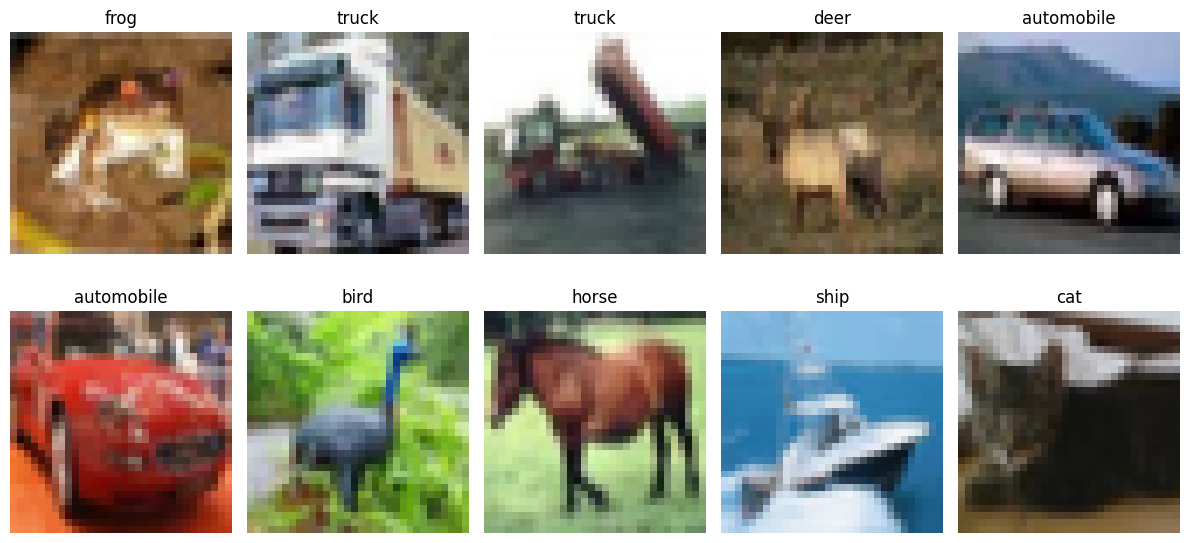

In [6]:
import matplotlib.pyplot as plt

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i])

    label = int(y_train[i])
    plt.title(class_names[label])

    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dropout,
    Flatten,
    Dense
)

model = Sequential([

    # First Convolution Layer
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(32, 32, 3)),

    MaxPooling2D((2, 2)),

    # Second Convolution Layer
    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    # Third Convolution Layer
    Conv2D(128, (3, 3), activation='relu'),

    # Dropout
    Dropout(0.25),

    # Flatten
    Flatten(),

    # Dense Layer
    Dense(128, activation='relu'),

    Dropout(0.5),

    # Output Layer
    Dense(10, activation='softmax')
])

print("CNN Model Created Successfully!")

c:\Users\HP\OneDrive\Desktop\AI_Image_Classification_DeepLearning\dataset\.venv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN Model Created Successfully!


In [9]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [10]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.3693 - loss: 1.7139 - val_accuracy: 0.4960 - val_loss: 1.3912
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.5094 - loss: 1.3668 - val_accuracy: 0.5730 - val_loss: 1.2147
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.5702 - loss: 1.2157 - val_accuracy: 0.6158 - val_loss: 1.1067
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.6116 - loss: 1.1082 - val_accuracy: 0.6442 - val_loss: 0.9963
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.6396 - loss: 1.0374 - val_accuracy: 0.6553 - val_loss: 0.9669
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.6641 - loss: 0.9663 - val_accuracy: 0.6813 - val_loss: 0.9128
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.6768 - loss: 0.9255 - val_accuracy: 0.6871 - val_loss: 0.8924
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 38ms/step - accuracy: 0.6936 - loss: 0.8766 - 

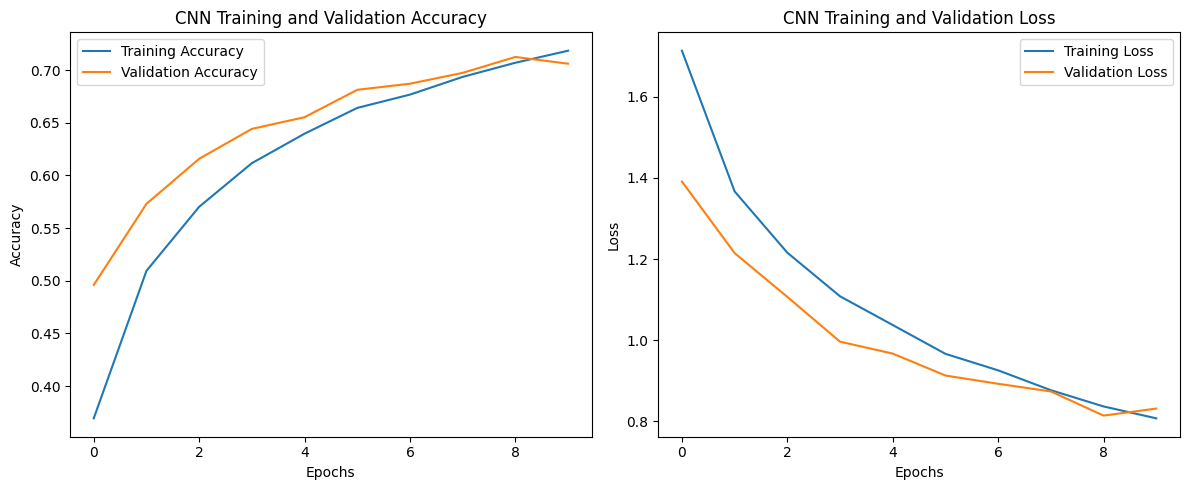

In [11]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7043 - loss: 0.8411
Test Accuracy: 70.43 %
Test Loss: 0.8411


In [13]:
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

y_true = y_test.flatten()

print("Predictions generated successfully!")
print("Predicted labels:", y_pred_classes[:10])
print("Actual labels:", y_true[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step
Predictions generated successfully!
Predicted labels: [3 1 8 0 4 6 9 6 3 1]
Actual labels: [3 8 8 0 6 6 1 6 3 1]


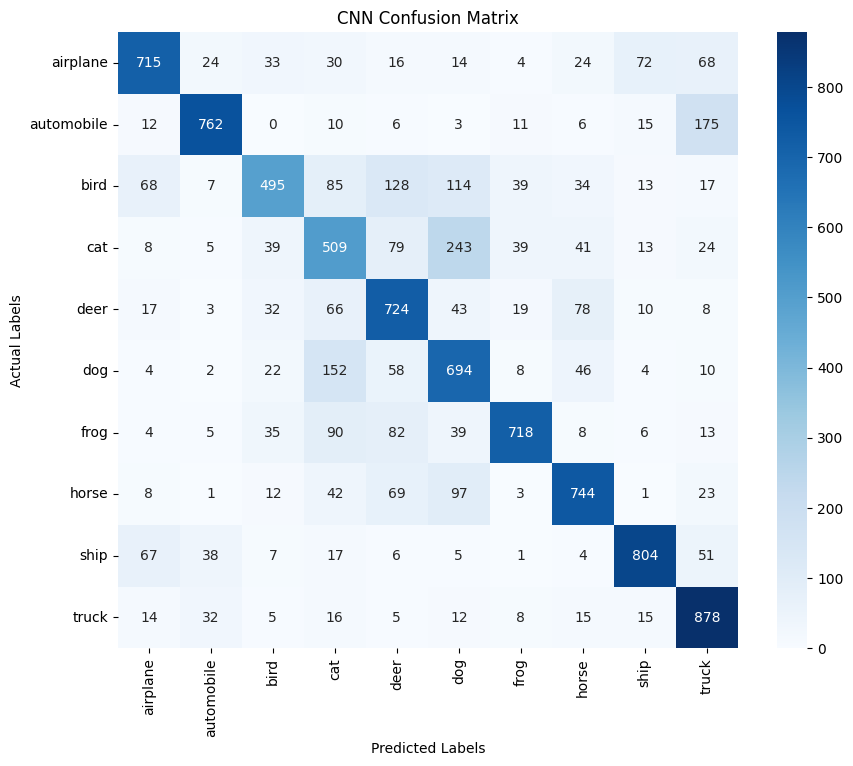

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.show()

In [15]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred_classes,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

    airplane       0.78      0.71      0.75      1000
  automobile       0.87      0.76      0.81      1000
        bird       0.73      0.49      0.59      1000
         cat       0.50      0.51      0.50      1000
        deer       0.62      0.72      0.67      1000
         dog       0.55      0.69      0.61      1000
        frog       0.84      0.72      0.78      1000
       horse       0.74      0.74      0.74      1000
        ship       0.84      0.80      0.82      1000
       truck       0.69      0.88      0.77      1000

    accuracy                           0.70     10000
   macro avg       0.72      0.70      0.70     10000
weighted avg       0.72      0.70      0.70     10000



In [16]:
model.save("cifar10_cnn_model.keras")

print("CNN model saved successfully!")

CNN model saved successfully!


## Task 3 – Transfer Learning

Implement **one pretrained CNN model** using Keras Applications.



**Choose any one:**

- VGG16
- ResNet50
- MobileNetV2
- EfficientNetB0
- InceptionV3

**Tasks:**

- Load pretrained model
- Freeze base layers
- Add custom classifier
- Train on the dataset
- Compare performance with the custom CNN

**Evaluate using:**

- Accuracy
- Loss
- Confusion Matrix
- Classification Report


In [17]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Resizing,
    Rescaling,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [18]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded successfully!


In [19]:
base_model.trainable = False

print("Pretrained layers frozen successfully!")
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

Pretrained layers frozen successfully!
Total layers: 154
Trainable: False


In [20]:
inputs = Input(shape=(32, 32, 3))

# Resize images
x = Resizing(96, 96)(inputs)

# Normalize for MobileNetV2
x = Rescaling(scale=2.0, offset=-1.0)(x)

# Pretrained MobileNetV2
x = base_model(x, training=False)

# Custom classifier
x = GlobalAveragePooling2D()(x)

x = Dense(128, activation='relu')(x)

x = Dropout(0.3)(x)

outputs = Dense(10, activation='softmax')(x)

transfer_model = Model(inputs, outputs)

print("Transfer Learning Model Created Successfully!")

Transfer Learning Model Created Successfully!


In [21]:
transfer_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [22]:
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Transfer Learning Model Compiled Successfully!")

Transfer Learning Model Compiled Successfully!


In [23]:
transfer_history = transfer_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 182s 281ms/step - accuracy: 0.7929 - loss: 0.6183 - val_accuracy: 0.8545 - val_loss: 0.4207
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 190s 304ms/step - accuracy: 0.8493 - loss: 0.4363 - val_accuracy: 0.8610 - val_loss: 0.4028
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 178s 284ms/step - accuracy: 0.8687 - loss: 0.3790 - val_accuracy: 0.8611 - val_loss: 0.4014
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 168s 269ms/step - accuracy: 0.8801 - loss: 0.3421 - val_accuracy: 0.8722 - val_loss: 0.3814
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 167s 268ms/step - accuracy: 0.8894 - loss: 0.3161 - val_accuracy: 0.8722 - val_loss: 0.3705
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 169s 270ms/step - accuracy: 0.8959 - loss: 0.2902 - val_accuracy: 0.8726 - val_loss: 0.3788
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 168s 269ms/step - accuracy: 0.9057 - loss: 0.2677 - val_accuracy: 0.8693 - val_loss: 0.3900
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 201s 268ms/step - accuracy: 0.9134 -

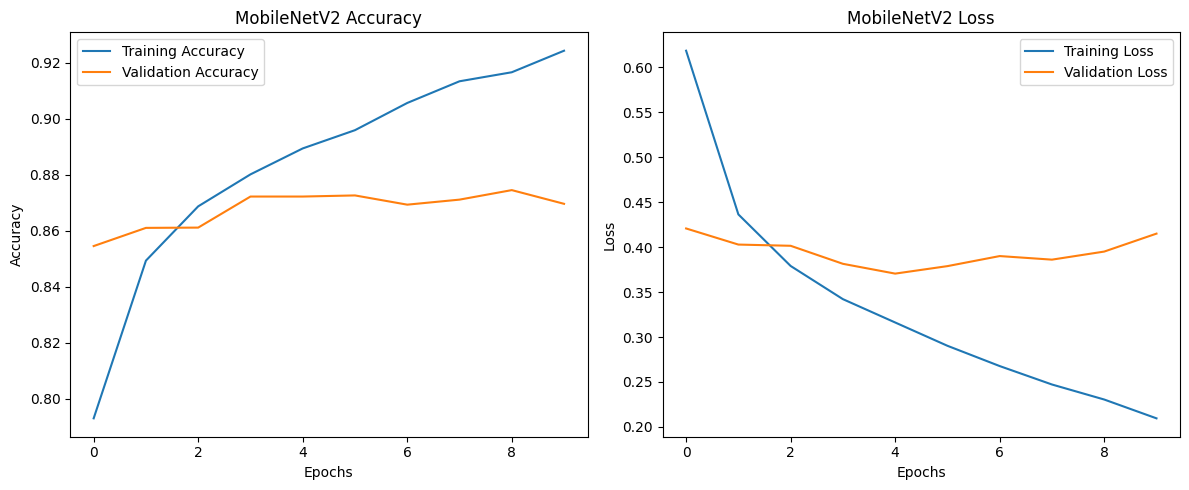

In [24]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    transfer_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    transfer_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    transfer_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    transfer_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('MobileNetV2 Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("MobileNetV2 Test Accuracy:",
      round(transfer_test_accuracy * 100, 2), "%")

print("MobileNetV2 Test Loss:",
      round(transfer_test_loss, 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 49s 151ms/step - accuracy: 0.8645 - loss: 0.4349
MobileNetV2 Test Accuracy: 86.45 %
MobileNetV2 Test Loss: 0.4349


In [26]:
transfer_predictions = transfer_model.predict(X_test)

transfer_pred_classes = np.argmax(
    transfer_predictions,
    axis=1
)

y_true = y_test.flatten()

print("Predictions generated successfully!")

print("Predicted labels:", transfer_pred_classes[:10])
print("Actual labels:", y_true[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 49s 151ms/step
Predictions generated successfully!
Predicted labels: [3 8 8 0 6 6 1 6 3 1]
Actual labels: [3 8 8 0 6 6 1 6 3 1]


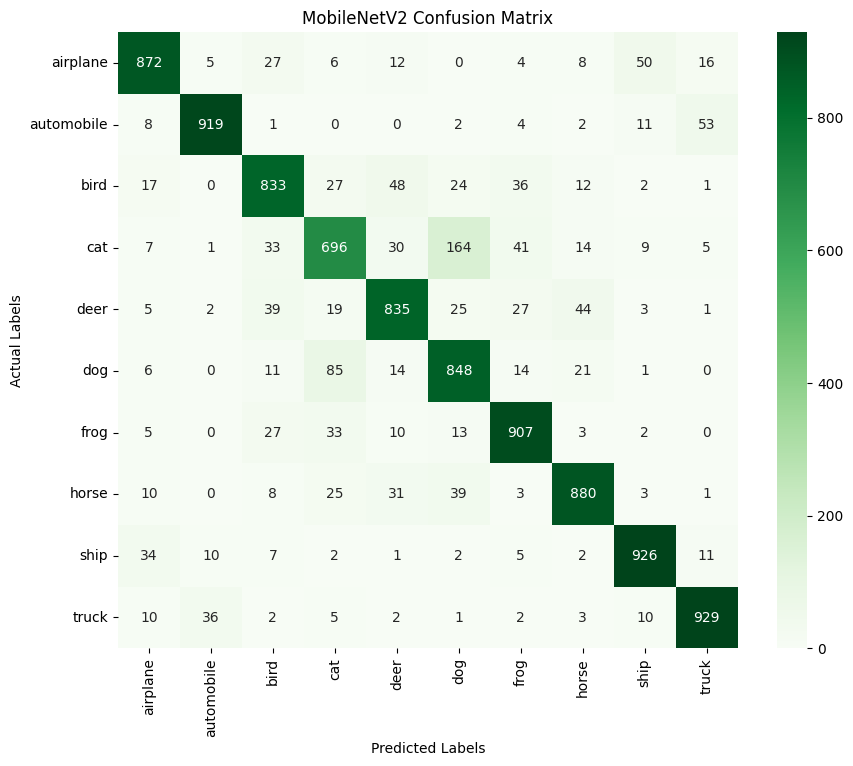

In [27]:
cm_transfer = confusion_matrix(
    y_true,
    transfer_pred_classes
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_transfer,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.show()

In [28]:
transfer_report = classification_report(
    y_true,
    transfer_pred_classes,
    target_names=class_names
)

print(transfer_report)

              precision    recall  f1-score   support

    airplane       0.90      0.87      0.88      1000
  automobile       0.94      0.92      0.93      1000
        bird       0.84      0.83      0.84      1000
         cat       0.78      0.70      0.73      1000
        deer       0.85      0.83      0.84      1000
         dog       0.76      0.85      0.80      1000
        frog       0.87      0.91      0.89      1000
       horse       0.89      0.88      0.88      1000
        ship       0.91      0.93      0.92      1000
       truck       0.91      0.93      0.92      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



In [29]:
transfer_model.save("mobilenetv2_cifar10_model.keras")

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


## Task 4 – Prediction and Visualization

Perform predictions on test images.



**Task:**

- Predict unseen images
- Display actual vs predicted labels
- Visualize correctly classified images
- Visualize misclassified images
- Plot training and validation Accuracy
- Plot training and validation Loss

In [30]:
import tensorflow as tf

transfer_model = tf.keras.models.load_model(
    "mobilenetv2_cifar10_model.keras"
)

print("MobileNetV2 model loaded successfully!")

MobileNetV2 model loaded successfully!


In [31]:
# Predict probabilities for test images
y_pred_prob = transfer_model.predict(X_test)

# Convert probabilities into class numbers
y_pred = np.argmax(y_pred_prob, axis=1)

# Convert actual labels into a 1D array
y_actual = y_test.reshape(-1)

print("Predictions completed!")
print("Actual labels:   ", y_actual[:10])
print("Predicted labels:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 63s 191ms/step
Predictions completed!
Actual labels:    [3 8 8 0 6 6 1 6 3 1]
Predicted labels: [3 8 8 0 6 6 1 6 3 1]


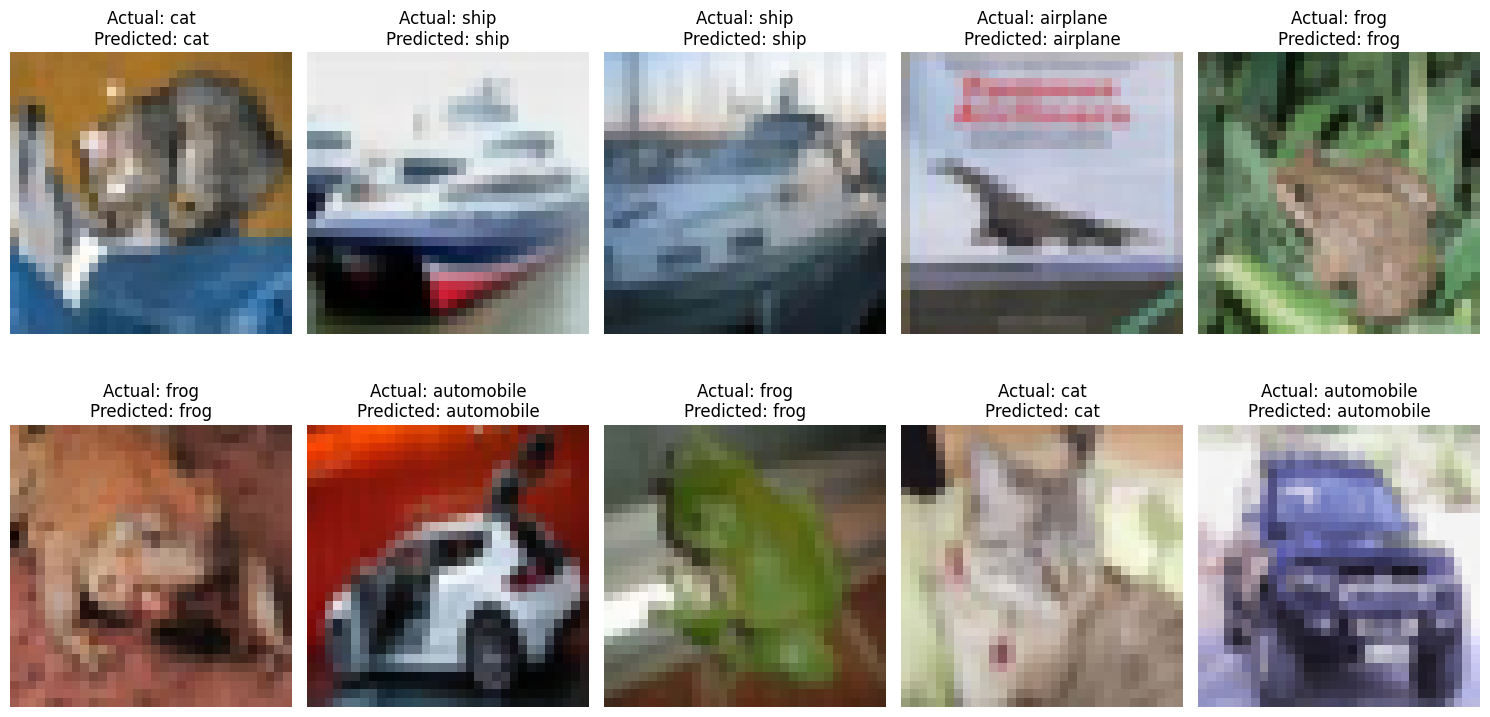

In [32]:
plt.figure(figsize=(15, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i])

    actual_label = class_names[y_actual[i]]
    predicted_label = class_names[y_pred[i]]

    plt.title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

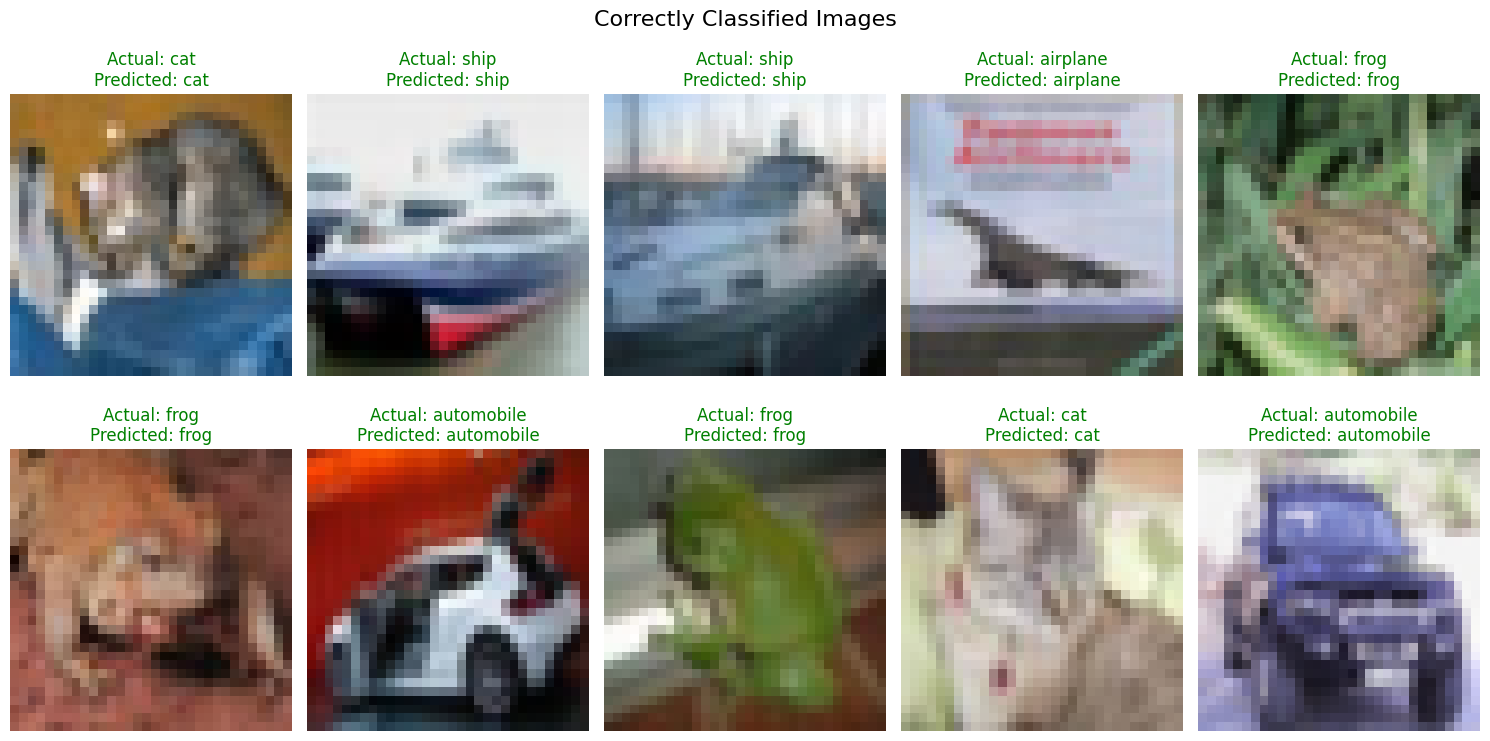

In [33]:
correct_indices = np.where(y_actual == y_pred)[0]

plt.figure(figsize=(15, 8))

for i, index in enumerate(correct_indices[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index])

    plt.title(
        f"Actual: {class_names[y_actual[index]]}\n"
        f"Predicted: {class_names[y_pred[index]]}",
        color="green"
    )

    plt.axis("off")

plt.suptitle("Correctly Classified Images", fontsize=16)
plt.tight_layout()
plt.show()

Total misclassified images: 1355


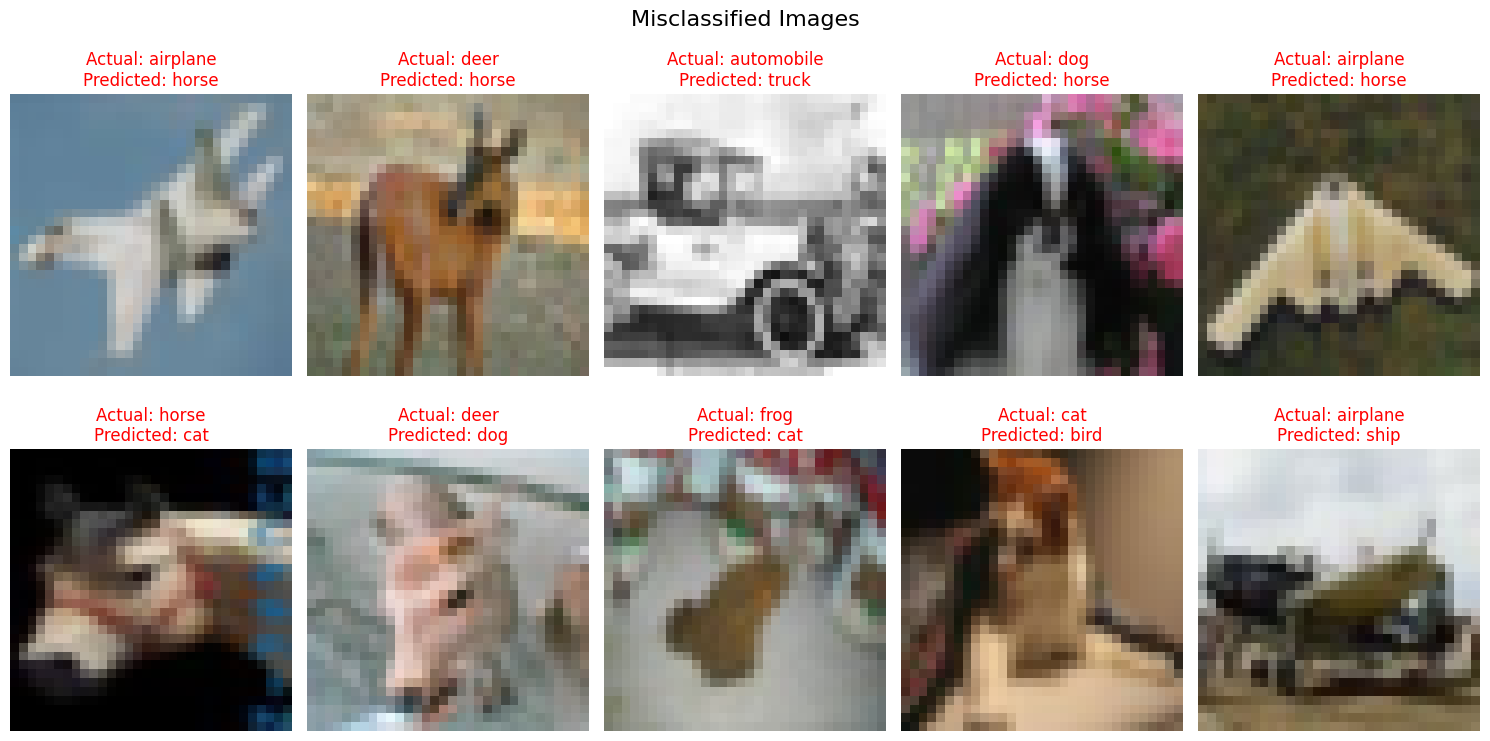

In [34]:
wrong_indices = np.where(y_actual != y_pred)[0]

print("Total misclassified images:", len(wrong_indices))

plt.figure(figsize=(15, 8))

for i, index in enumerate(wrong_indices[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index])

    plt.title(
        f"Actual: {class_names[y_actual[index]]}\n"
        f"Predicted: {class_names[y_pred[index]]}",
        color="red"
    )

    plt.axis("off")

plt.suptitle("Misclassified Images", fontsize=16)
plt.tight_layout()
plt.show()

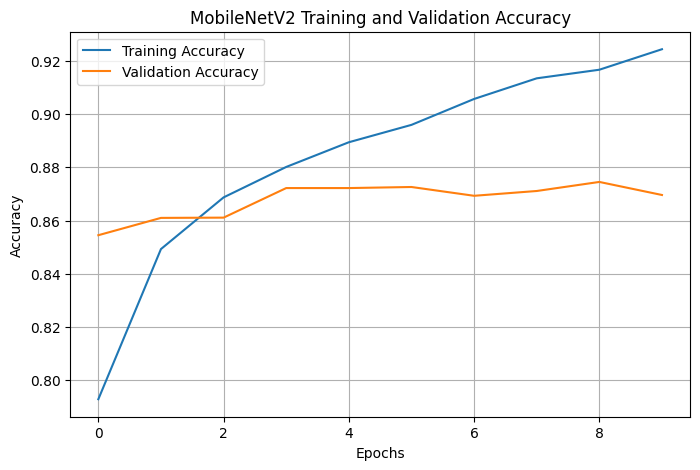

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    transfer_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    transfer_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("MobileNetV2 Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

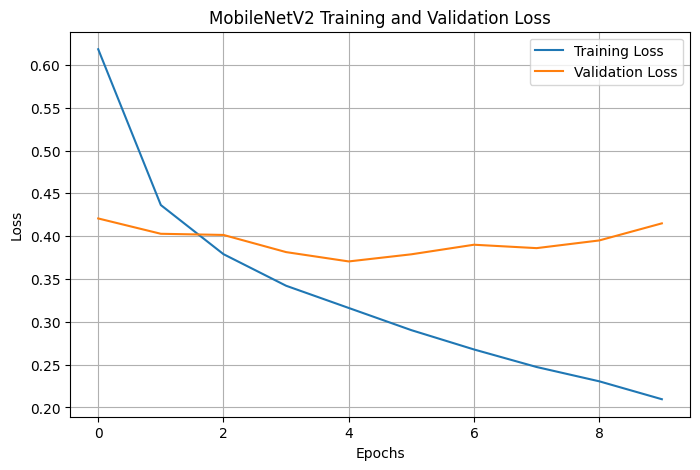

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    transfer_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    transfer_history.history['val_loss'],
    label='Validation Loss'
)

plt.title("MobileNetV2 Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [37]:
total_images = len(y_actual)
correct_count = len(correct_indices)
wrong_count = len(wrong_indices)

print("========== PREDICTION SUMMARY ==========")
print("Total Test Images:", total_images)
print("Correct Predictions:", correct_count)
print("Incorrect Predictions:", wrong_count)
print("Test Accuracy:", round((correct_count / total_images) * 100, 2), "%")

========== PREDICTION SUMMARY ==========
Total Test Images: 10000
Correct Predictions: 8645
Incorrect Predictions: 1355
Test Accuracy: 86.45 %


## Task 5 – Model Analysis and Documentation

**Task:**

- Comparison between CNN and Transfer Learning
- Model performance analysis
- Advantages and limitations of both approaches
- Challenges faced during implementation
- Real-world applications
- Future improvements

In [41]:
import pandas as pd

comparison_data = {
    "Model": ["MobileNetV2"],
    "Approach": ["Transfer Learning"],
    "Test Accuracy (%)": [86.45]
}

comparison_df = pd.DataFrame(comparison_data)

print("========== MODEL PERFORMANCE ==========")
print(comparison_df)

========== MODEL PERFORMANCE ==========
         Model           Approach  Test Accuracy (%)
0  MobileNetV2  Transfer Learning              86.45


In [43]:
import tensorflow as tf

print("========== AVAILABLE TRAINED MODELS ==========")

for name, obj in globals().copy().items():
    if isinstance(obj, tf.keras.Model):
        print("\nVariable Name:", name)
        print("Model Name:", obj.name)
        print("Input Shape:", obj.input_shape)
        print("Output Shape:", obj.output_shape)

========== AVAILABLE TRAINED MODELS ==========

Variable Name: model
Model Name: sequential
Input Shape: (None, 32, 32, 3)
Output Shape: (None, 10)

Variable Name: base_model
Model Name: mobilenetv2_1.00_96
Input Shape: (None, 96, 96, 3)
Output Shape: (None, 3, 3, 1280)

Variable Name: transfer_model
Model Name: functional_1
Input Shape: (None, 32, 32, 3)
Output Shape: (None, 10)


In [44]:
# Evaluate Custom CNN
cnn_loss, cnn_accuracy = model.evaluate(
    X_test, y_test, verbose=1
)

# Evaluate MobileNetV2
transfer_loss, transfer_accuracy = transfer_model.evaluate(
    X_test, y_test, verbose=1
)

print("\n========== MODEL EVALUATION ==========")

print("Custom CNN Test Accuracy:",
      round(cnn_accuracy * 100, 2), "%")

print("MobileNetV2 Test Accuracy:",
      round(transfer_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7043 - loss: 0.8411
313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 115ms/step - accuracy: 0.8645 - loss: 0.4349

========== MODEL EVALUATION ==========
Custom CNN Test Accuracy: 70.43 %
MobileNetV2 Test Accuracy: 86.45 %


In [45]:
import pandas as pd

comparison_data = {
    "Model": ["Custom CNN", "MobileNetV2"],
    "Approach": ["Built from Scratch", "Transfer Learning"],
    "Test Accuracy (%)": [
        round(cnn_accuracy * 100, 2),
        round(transfer_accuracy * 100, 2)
    ],
    "Test Loss": [
        round(cnn_loss, 4),
        round(transfer_loss, 4)
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("\n========== CNN vs TRANSFER LEARNING ==========")
print(comparison_df.to_string(index=False))


========== CNN vs TRANSFER LEARNING ==========
      Model           Approach  Test Accuracy (%)  Test Loss
 Custom CNN Built from Scratch              70.43     0.8411
MobileNetV2  Transfer Learning              86.45     0.4349


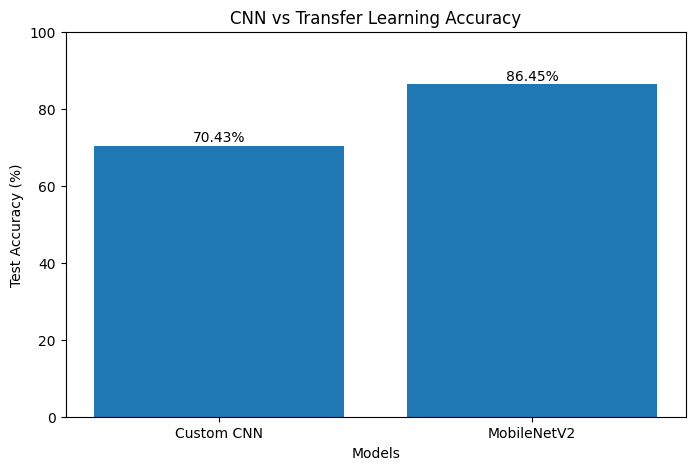

In [46]:
import matplotlib.pyplot as plt

models = ["Custom CNN", "MobileNetV2"]
accuracies = [
    cnn_accuracy * 100,
    transfer_accuracy * 100
]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title("CNN vs Transfer Learning Accuracy")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%",
             ha="center")

plt.show()

In [47]:
from pathlib import Path

# Identify project directory
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

# Create folders
models_dir = PROJECT_DIR / "models"
outputs_dir = PROJECT_DIR / "outputs"

models_dir.mkdir(exist_ok=True)
outputs_dir.mkdir(exist_ok=True)

# Save Custom CNN
model.save(models_dir / "custom_cnn.keras")

# Save MobileNetV2 Transfer Learning model
transfer_model.save(models_dir / "mobilenetv2_model.keras")

print("Both models saved successfully!")

Both models saved successfully!


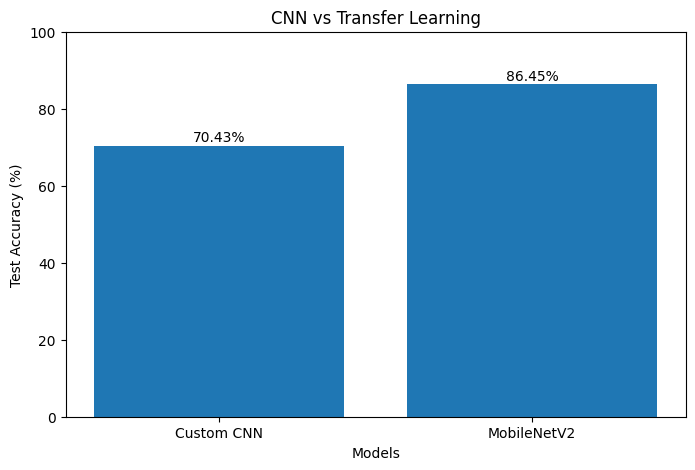

Comparison graph saved!


In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

models = ["Custom CNN", "MobileNetV2"]
accuracies = [
    cnn_accuracy * 100,
    transfer_accuracy * 100
]

plt.bar(models, accuracies)

plt.title("CNN vs Transfer Learning")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.savefig(
    outputs_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison graph saved!")

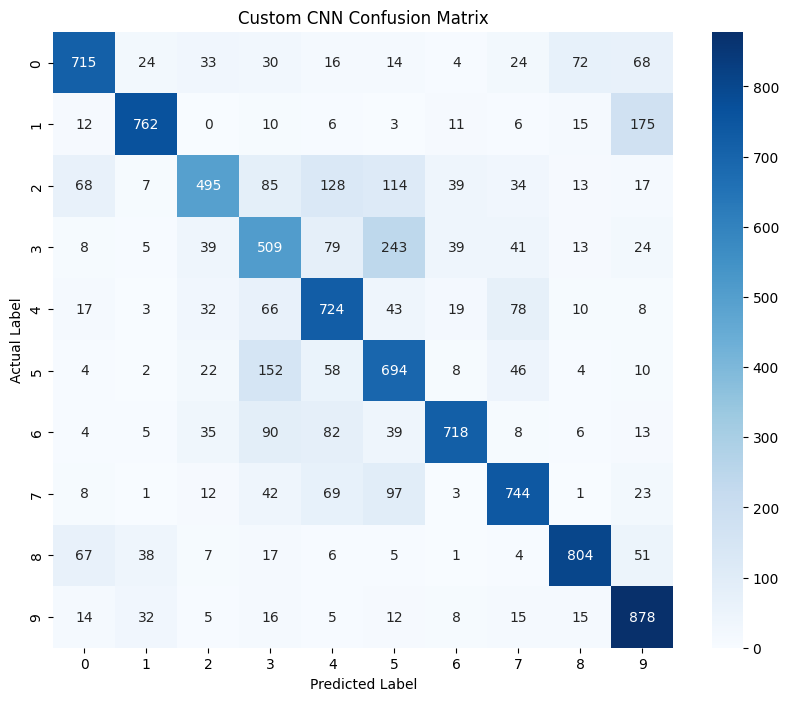

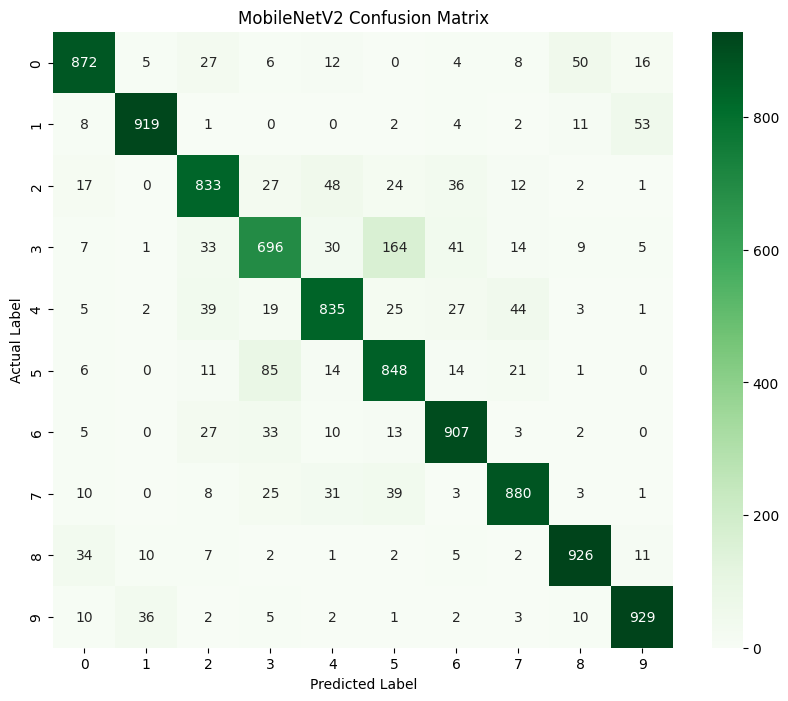

Both confusion matrices saved!


In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

# Custom CNN confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Custom CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.savefig(
    outputs_dir / "cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# MobileNetV2 confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm_transfer, annot=True, fmt="d", cmap="Greens")

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.savefig(
    outputs_dir / "mobilenet_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Both confusion matrices saved!")